# AdaJEPA: a world model that keeps learning while it plans

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/adajepa.ipynb)

[AdaJEPA](https://arxiv.org/abs/2606.32026) ([code](https://github.com/agentic-learning-ai-lab/adajepa)) does not freeze its world model after training. Inside the planning loop it runs the first planned action, adds the transition it just saw to a buffer of the 5 most recent ones, and takes one gradient step of the latent prediction loss on that buffer before planning again. Only the last predictor block and the encoder's head change, and every episode starts again from the trained weights. Here the model learns PLDM's Two-Rooms task from clean images, then has to plan in rooms that look or move differently.

In [1]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import time

import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import TwoRooms
from torch_world.models import AdaJEPA, PLDMEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
SIZE = 32  # small images keep the notebook fast, even on a CPU

## Data and model
The point wanders at random in the clean rooms, keeping its previous action with probability 0.8: no rewards, no goals. A small IMPALA-style CNN maps each frame to a 64-d latent, and a two-block causal transformer reads the last 3 latents, each concatenated with its action embedding, to predict the next ones.

In [3]:
data = TwoRooms(batch_size=1024, size=SIZE, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=4), batch_size=128, shuffle=True, drop_last=True)

model = AdaJEPA(PLDMEncoder(img_size=SIZE, latent_dim=64), action_dim=2, embed_dim=64, action_embed_dim=8,
                depth=2, num_heads=2, head_dim=32, mlp_dim=256).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

0.24M parameters


## Train
Teacher-forced one-step prediction against stop-gradient targets, with the temporal straightening term of the paper's base model and VCReg variance and covariance terms on the latents.

trained in 117.9 min on cpu


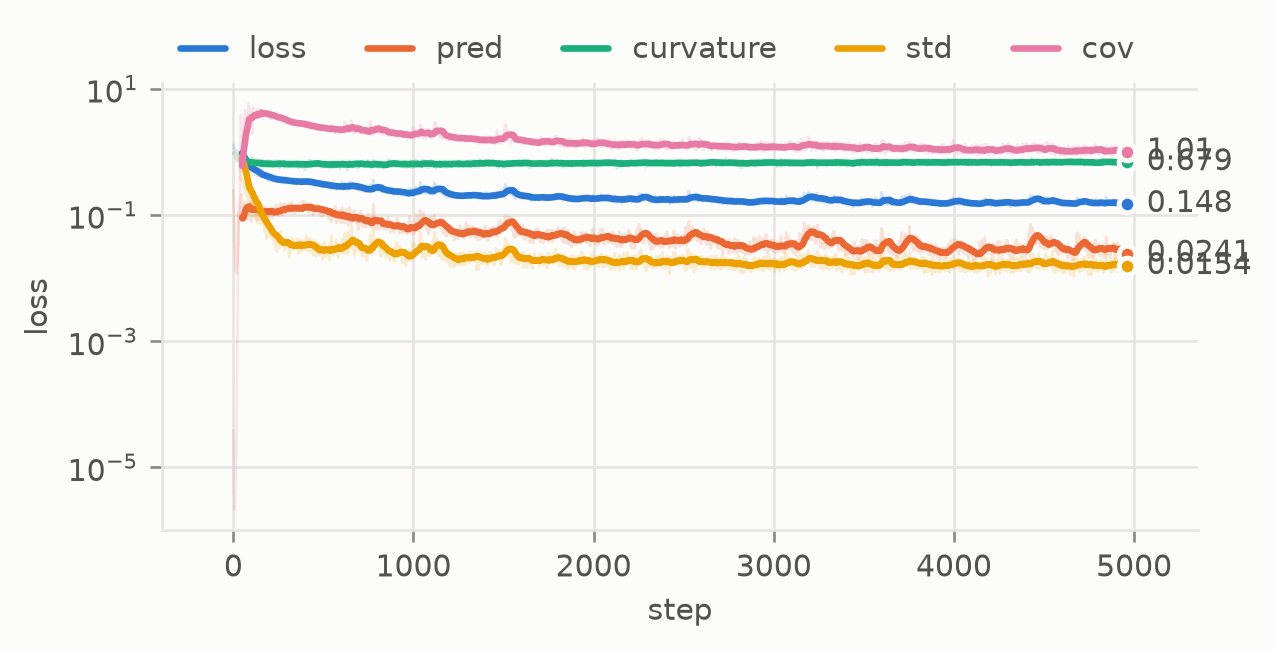

In [4]:
tic = time.time()
log = fit(model, loader, epochs=10, lr=5e-4, clip=1.0)
print(f"trained in {(time.time() - tic) / 60:.1f} min on {device}")
plots.curves(log, smooth=50)

## The test rooms
The same task in shifted rooms: a floor tinted blue (a background shift), and three colored discs that drift on their own, unaffected by the actions. Goal images are drawn in the same rooms, so the goal is reachable, but the frozen model has never seen frames like these.

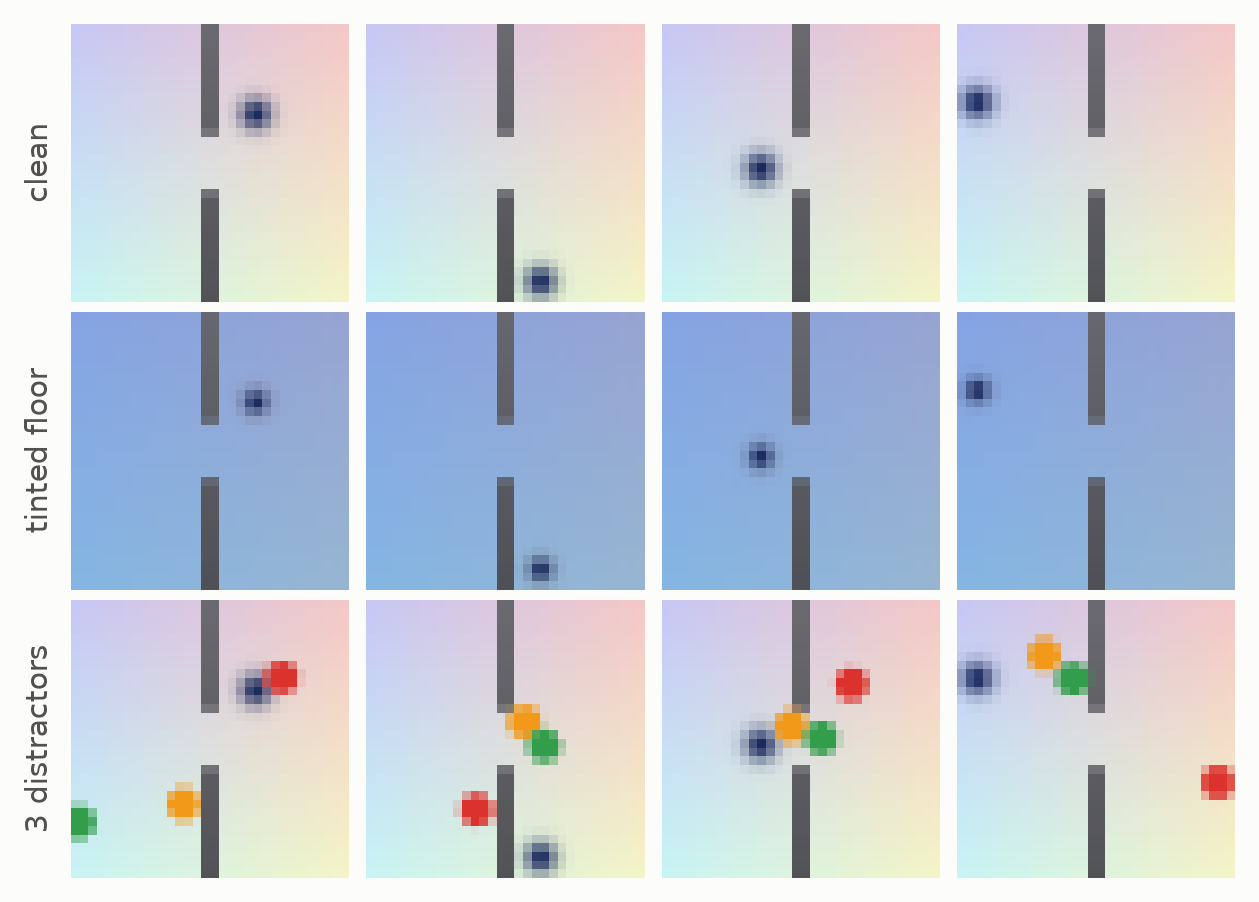

In [5]:
shifts = {"tinted floor": dict(floor=(0.35, 0.55, 0.85)), "3 distractors": dict(distractors=3)}
clean = TwoRooms(batch_size=4, size=SIZE)
start, _ = clean.tasks(generator=torch.Generator().manual_seed(1))
views = [clean.render(start)]
for kwargs in shifts.values():
    env = TwoRooms(batch_size=4, size=SIZE, **kwargs)
    env.reset(start, generator=torch.Generator().manual_seed(1))
    views.append(env.render())
plots.images(torch.cat(views), rows=["clean", *shifts], ncols=4)

## Plan and adapt
CEM searches 10-step action sequences, scored by the mean latent distance to the goal along the imagined path; the first action runs and the planner replans every step. The frozen model plans the same way. AdaJEPA adds one Adam step before every plan, on the last 5 transitions of its own episode, at learning rate 5e-4 for the last predictor block and 1e-5 for the encoder head. Random actions are the floor. Starts and goals are in opposite rooms.

In [6]:
planner = CEM(horizon=10, action_dim=2, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1), objective="path")
conditions = {"clean": {}, **shifts}
runs, adapted = {}, {}
for name, kwargs in conditions.items():
    env = TwoRooms(batch_size=32, size=SIZE, device=device, **kwargs)
    start, goal = env.tasks(generator=torch.Generator().manual_seed(2))
    env.reset(goal, generator=torch.Generator().manual_seed(3))
    goal_images = env.render(goal)
    adapted[name] = model.policy(planner, goal_images, buffer=5, steps=1, lr=5e-4, encoder_lr=1e-5)
    policies = {
        "frozen": evaluation.goal_policy(model, planner, goal_images),
        "AdaJEPA": adapted[name],
        "random actions": evaluation.random_policy(env),
    }
    tic = time.time()
    runs[name] = evaluation.goal_reaching(env, policies, start, goal, steps=50, success="reached")
    print(f"{name} ({(time.time() - tic) / 60:.1f} min)")
    print(runs[name], end="\n\n")

clean (19.7 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
frozen             44% [28%, 61%]      44%    8.64           0.291     0.441   0.141       0.613   7.99e+03
AdaJEPA            69% [51%, 82%]      69%    17.5          0.0341     0.935   0.218       0.635   1.57e+04
random actions       9% [3%, 24%]       9%    13.3           0.644    -0.039  0.0101        1.05      0.124



tinted floor (18.7 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
frozen             41% [26%, 58%]      41%    10.8           0.293     0.366   0.127       0.658   7.18e+03
AdaJEPA            72% [55%, 84%]      72%    16.6          0.0351     0.932   0.231       0.638   1.52e+04
random actions       9% [3%, 24%]       9%    21.7            0.55    0.0523  0.0118        1.04      0.309



3 distractors (19.4 min)
                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
frozen             31% [18%, 49%]      31%    12.5           0.361     0.274   0.085       0.677   7.44e+03
AdaJEPA            47% [31%, 64%]      47%    16.3           0.167     0.354   0.133       0.634   1.58e+04
random actions       3% [1%, 16%]       3%      38           0.549     0.116 0.00443        1.03     0.0525



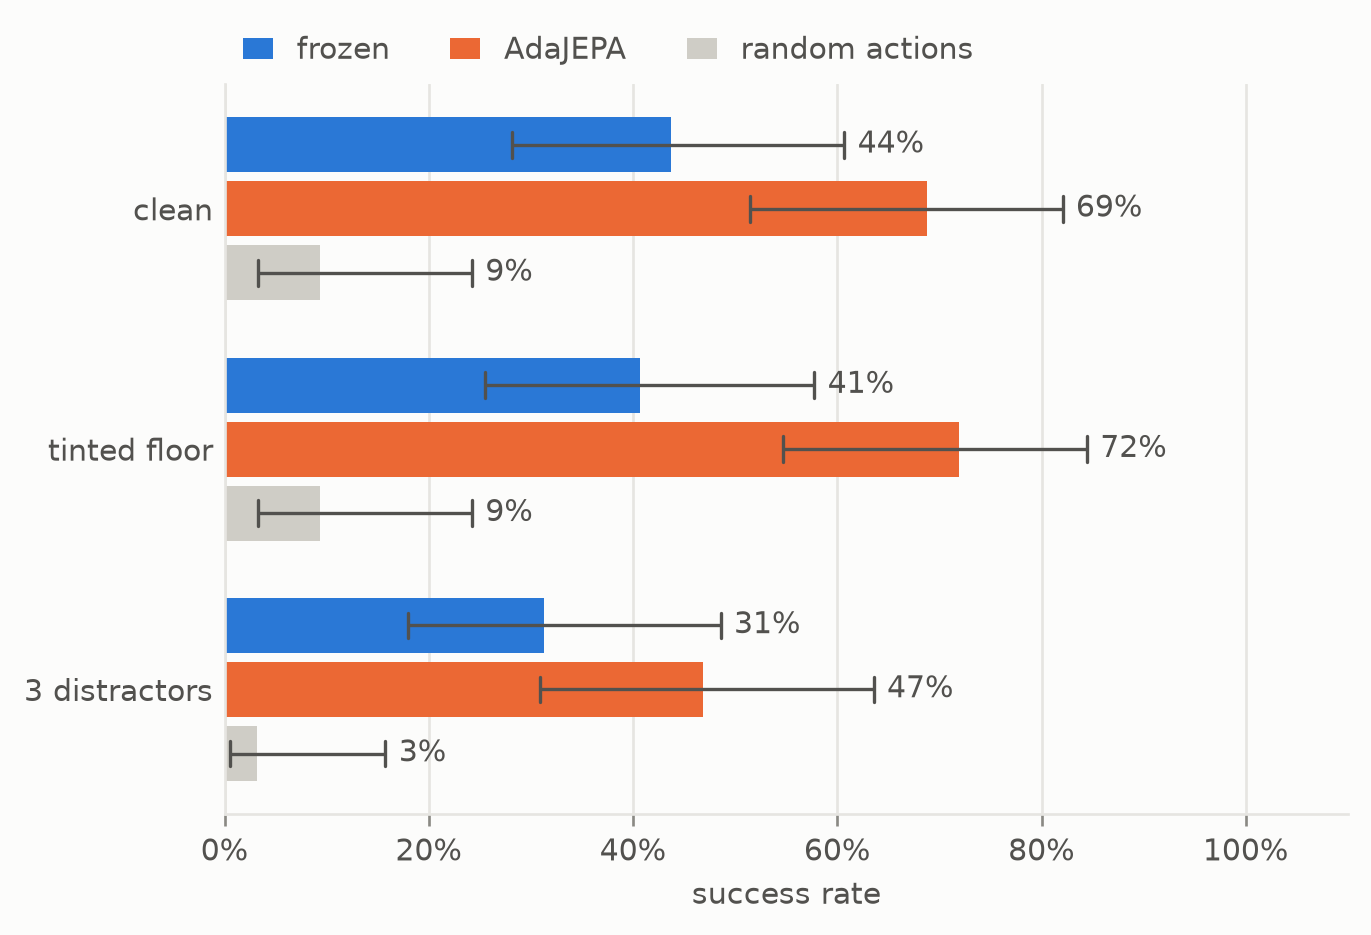

In [7]:
plots.bars({name: run.intervals() for name, run in runs.items()}, xlabel="success rate", baseline="random actions")

## What the adaptation sees
The loss of each adaptation step, averaged over the episodes, along the episode: the one-step prediction error on the recent transitions, before the step.

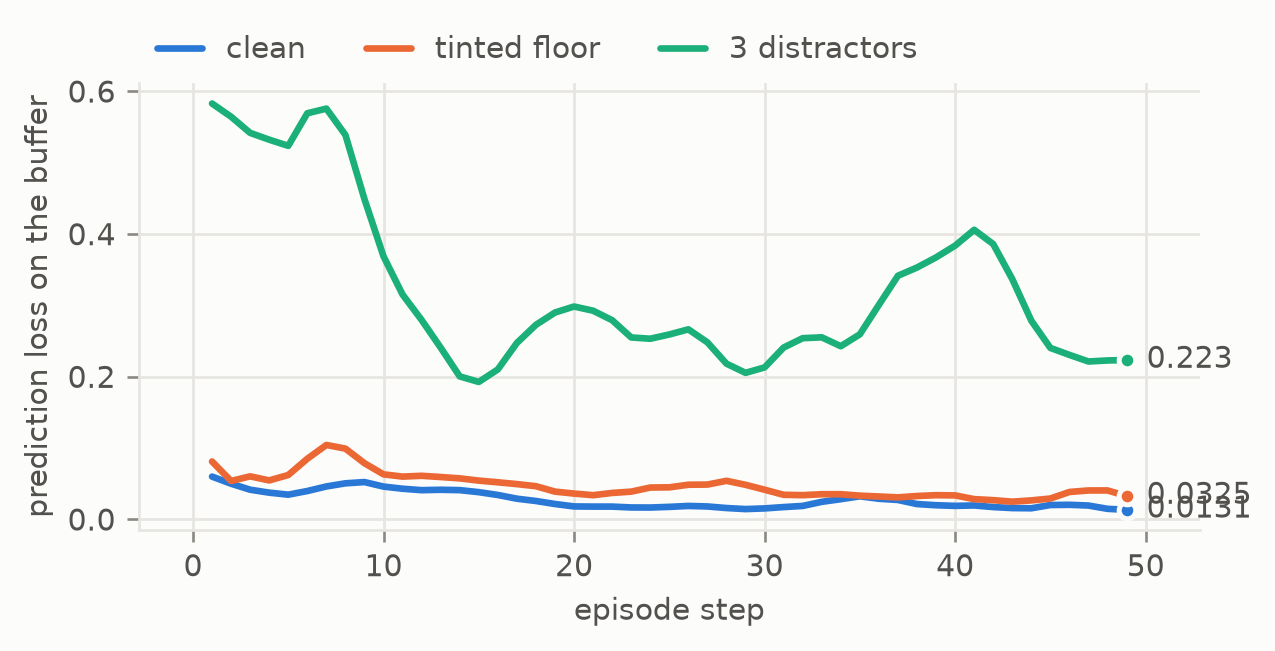

In [8]:
curves = {name: (range(1, len(p.losses) + 1), torch.tensor(p.losses).mean(1).tolist()) for name, p in adapted.items()}
plots.curves(curves, smooth=1, logy=False, xlabel="episode step", ylabel="prediction loss on the buffer")

## Summary
Adapting while planning paid off here, but not for the reason the shifts were meant to show. Across the wall, with 32 tasks per condition, AdaJEPA reached the goal more often than the same model frozen in every condition: 69% [51, 82] against 44% [28, 61] in the clean rooms, 72% [55, 84] against 41% [26, 58] with the tinted floor, and 47% [31, 64] against 31% [18, 49] with three distractors. Random actions reached 3 to 9%.

The tinted floor did not hurt the frozen model (41% against 44% clean). Its prediction loss on the buffer stays near the clean one, so this model's latents largely ignore the floor color. The distractors are the shift that hurts: the frozen model drops to 31%, its prediction loss starts ten times higher, and adaptation brings it down by a factor of three over the first fifteen steps. The gain there is the smallest, though, and its interval overlaps the frozen one.

Most of the gain comes in the clean rooms too, as in the paper's seen-shape results. A few gradient steps on the episode's own transitions correct this small model's errors near where the agent actually is, whatever the shift. The frozen baseline plans each episode with the same CEM settings, batched; only the random draws differ.

This run used a CPU on Sparks, with no GPU free: 118 minutes of training and about 19 minutes of planning per condition, where one CEM plan costs about 8 s for the batch of 32 frozen episodes and about 0.5 s per adapted episode. The paper adapts a larger ResNet and ViT model, planned with gradient descent over action chunks; see the [model page](../../docs/models/jepa/adajepa.md) for every difference.